# Customer Data: Ordinal Encoding Analysis

This notebook explores `customer.csv` and demonstrates **ordinal encoding** in a careful, interpretable way. Ordinal encoding maps categories with a real order to integer ranks. We will encode `review` as Poor < Average < Good and `education` as School < UG < PG. These orders are explicit assumptions and should be checked against the meaning of the data.

`gender` has no natural ranking, so we will not assign it arbitrary numbers. We will show one-hot encoding for it as a nominal feature. `purchased` is the Yes/No outcome; it is shown and encoded separately from predictors to avoid mixing the target into feature preprocessing.


## 1. Load libraries and data

The CSV should be saved in the same folder as this notebook. We begin by checking the table shape and previewing a few records.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, LabelEncoder

sns.set_theme(style="whitegrid", context="notebook", palette="Set2")
DATA_PATH = Path("customer.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Expected customer.csv beside this notebook: {DATA_PATH.resolve()}")
df = pd.read_csv(DATA_PATH)
print(f"Dataset shape: {df.shape[0]} rows × {df.shape[1]} columns")
display(df.head(10))

Dataset shape: 50 rows × 5 columns


,age,gender,review,education,purchased
0,30,Female,Average,School,No
1,68,Female,Poor,UG,No
2,70,Female,Good,PG,No
3,72,Female,Good,PG,No
4,16,Female,Average,UG,No
5,31,Female,Average,School,Yes
6,18,Male,Good,School,No
7,60,Female,Poor,School,Yes
8,65,Female,Average,UG,No
9,74,Male,Good,UG,Yes


## 2. Understand the columns and check data quality

- `age`: numeric customer attribute
- `gender`: nominal category, with no intrinsic order
- `review`: ordered satisfaction rating
- `education`: ordered attainment level, if the category meanings match the assumed progression
- `purchased`: binary outcome (Yes/No)

Before encoding, inspect types, missing values, duplicates, and unique category spellings. Encoders need consistent category values; unexpected spellings or missing values must be addressed deliberately.

In [2]:
display(df.dtypes.to_frame("dtype"))
print("Missing values by column:")
display(df.isna().sum().rename("missing_count").to_frame())
print("Duplicate rows:", df.duplicated().sum())
for col in df.select_dtypes(include="object").columns:
    print(f"{col} categories:", sorted(df[col].dropna().unique().tolist()))
print("Age summary:")
display(df["age"].describe().to_frame().T)

,dtype
age,int64
gender,object
review,object
education,object
purchased,object


Missing values by column:


,missing_count
age,0
gender,0
review,0
education,0
purchased,0


Duplicate rows: 1
gender categories: ['Female', 'Male']
review categories: ['Average', 'Good', 'Poor']
education categories: ['PG', 'School', 'UG']
purchased categories: ['No', 'Yes']
Age summary:


,count,mean,std,min,25%,50%,75%,max
age,50.0,54.16,25.658161,15.0,30.25,57.0,74.0,98.0


In [3]:
required = {"age", "gender", "review", "education", "purchased"}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Required columns missing: {sorted(missing)}")
if df[list(required)].isna().any().any():
    raise ValueError("Missing values detected. Decide how to handle them before encoding.")

## 3. Explore the original categories

These charts show how observations are distributed among the category values and how purchase outcomes vary across them. Bars show counts rather than causal effects: this small dataset is descriptive and does not establish that any category causes a purchase.

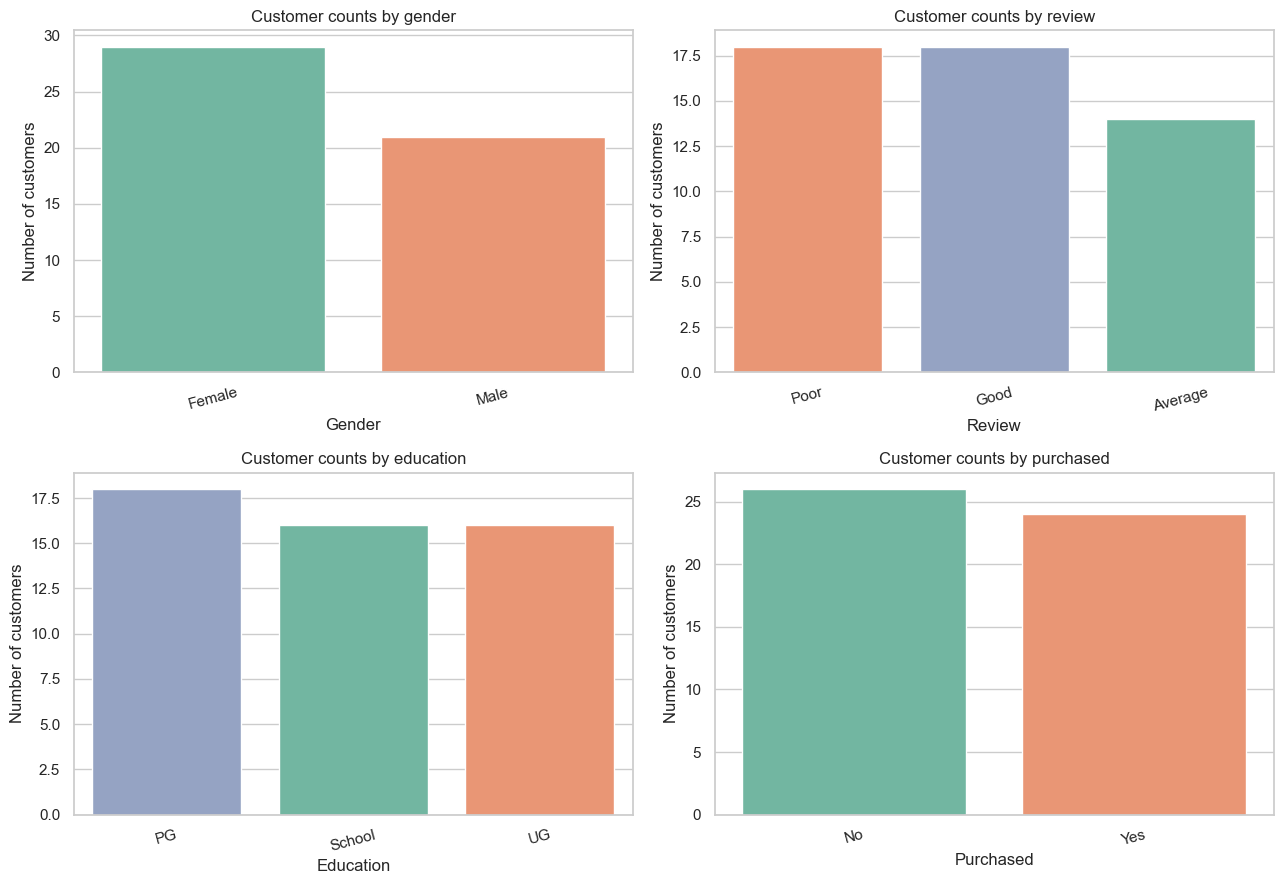

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.flat, ["gender", "review", "education", "purchased"]):
    order = df[col].value_counts().index.tolist()
    sns.countplot(data=df, x=col, order=order, hue=col, legend=False, ax=ax)
    ax.set_title(f"Customer counts by {col}")
    ax.set_xlabel(col.title())
    ax.set_ylabel("Number of customers")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

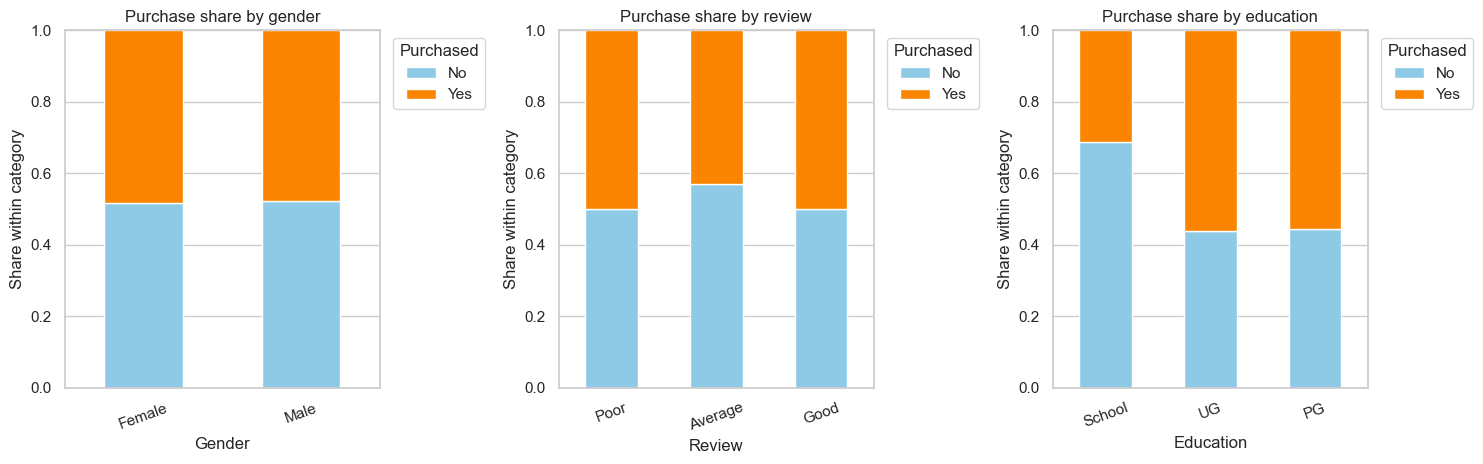

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, col, order in zip(axes, ["gender", "review", "education"],
                           [None, ["Poor", "Average", "Good"], ["School", "UG", "PG"]]):
    tab = pd.crosstab(df[col], df["purchased"], normalize="index").reindex(order) if order else pd.crosstab(df[col], df["purchased"], normalize="index")
    tab.plot(kind="bar", stacked=True, ax=ax, color=["#8ecae6", "#fb8500"], ylim=(0, 1))
    ax.set_title(f"Purchase share by {col}")
    ax.set_ylabel("Share within category")
    ax.set_xlabel(col.title())
    ax.legend(title="Purchased", bbox_to_anchor=(1.02, 1), loc="upper left")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

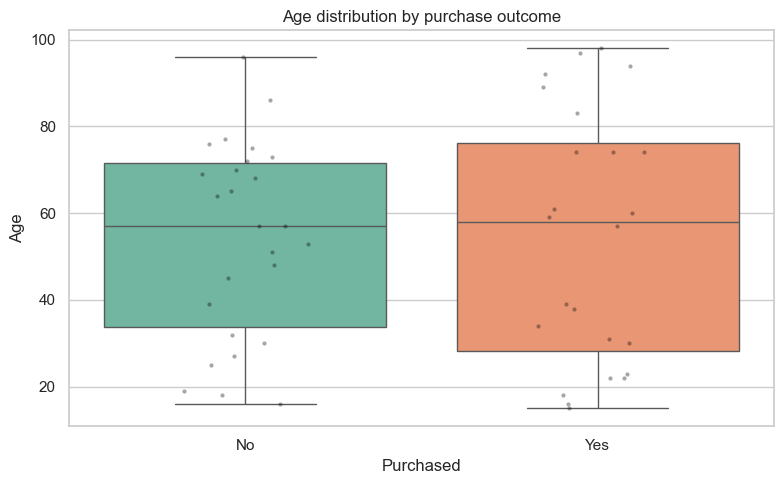

In [6]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="purchased", y="age", hue="purchased", legend=False, palette="Set2")
sns.stripplot(data=df, x="purchased", y="age", color="black", alpha=0.35, jitter=0.18, size=3)
plt.title("Age distribution by purchase outcome")
plt.xlabel("Purchased")
plt.ylabel("Age")
plt.tight_layout()
plt.show()

## 4. Decide which encoding fits each column

| Column | Type | Encoding choice | Reason |
|---|---|---|---|
| `review` | Ordinal | Poor=0, Average=1, Good=2 | Categories have an intuitive ordered progression |
| `education` | Ordinal | School=0, UG=1, PG=2 | Represents increasing education level, assuming these labels mean that |
| `gender` | Nominal | One-hot encoding | Integer ranks would invent an order |
| `purchased` | Binary target | Yes=1, No=0 | Target is represented separately from model inputs |

Ordinal codes communicate rank, but **do not prove equal spacing** between levels. For example, the numerical gap between School and UG may not be quantitatively the same as the gap between UG and PG. A model that assumes numeric distances can interpret those codes accordingly.

## 5. Define the category order and validate it

Providing category order explicitly makes the mapping reproducible and prevents an encoder from choosing an unintended alphabetical order. If the dataset includes an unknown category, the checks below stop execution so the category can be reviewed.

In [7]:
review_order = ["Poor", "Average", "Good"]
education_order = ["School", "UG", "PG"]

assert set(df["review"].unique()) <= set(review_order), "Unexpected review category found"
assert set(df["education"].unique()) <= set(education_order), "Unexpected education category found"
print("Review order:", review_order)
print("Education order:", education_order)

Review order: ['Poor', 'Average', 'Good']
Education order: ['School', 'UG', 'PG']


## 6. Split before learning preprocessing

For a modeling workflow, reserve the test set before fitting encoders. Here the category order is known from meaning and specified manually, so applying the mapping does not estimate a statistic from the full dataset. We still keep train and test separate to demonstrate a clean modeling setup and fit the nominal encoder on training data only.

In [8]:
X = df[["age", "gender", "review", "education"]].copy()
y = df["purchased"].map({"No": 0, "Yes": 1})
if y.isna().any():
    raise ValueError("Unexpected purchased value; expected only Yes/No.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print(f"Train rows: {len(X_train)} | Test rows: {len(X_test)}")
print("Train purchase rate:", round(y_train.mean(), 3))
print("Test purchase rate:", round(y_test.mean(), 3))

Train rows: 37 | Test rows: 13
Train purchase rate: 0.486
Test purchase rate: 0.462


## 7. Apply ordinal encoding to ordered columns

`OrdinalEncoder` is configured with the meaningful order for each column. Both train and test are transformed with the same encoder. The generated integer codes are ranks starting at zero.

In [9]:
ordinal_encoder = OrdinalEncoder(
    categories=[review_order, education_order],
    dtype=np.int64,
    handle_unknown="use_encoded_value", unknown_value=-1
)
ordered_cols = ["review", "education"]
train_ordinal = pd.DataFrame(
    ordinal_encoder.fit_transform(X_train[ordered_cols]),
    columns=["review_encoded", "education_encoded"], index=X_train.index
)
test_ordinal = pd.DataFrame(
    ordinal_encoder.transform(X_test[ordered_cols]),
    columns=["review_encoded", "education_encoded"], index=X_test.index
)
display(train_ordinal.head())

,review_encoded,education_encoded
21,1,2
5,1,0
34,1,0
13,1,0
42,2,2


## 8. Handle nominal gender separately

One-hot encoding creates a separate 0/1 indicator for each gender category. The columns do not imply that one category is higher or lower than another. We fit the encoder on training values and use `handle_unknown="ignore"` so a previously unseen test category does not crash transformation (it produces all zeros for the encoded gender columns).

In [10]:
gender_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.int64)
train_gender_array = gender_encoder.fit_transform(X_train[["gender"]])
test_gender_array = gender_encoder.transform(X_test[["gender"]])
gender_columns = [f"gender_{category}" for category in gender_encoder.categories_[0]]
train_gender = pd.DataFrame(train_gender_array, columns=gender_columns, index=X_train.index)
test_gender = pd.DataFrame(test_gender_array, columns=gender_columns, index=X_test.index)
print("One-hot columns:", gender_columns)
display(train_gender.head())

One-hot columns: ['gender_Female', 'gender_Male']


,gender_Female,gender_Male
21,0,1
5,1,0
34,0,1
13,1,0
42,1,0


## 9. Assemble the model-ready encoded data

Age remains numeric and unencoded. We concatenate it with the ordinal ranks and one-hot gender indicators. The purchase outcome stays in `y_train` and `y_test`, not among the predictors.

In [11]:
X_train_encoded = pd.concat(
    [X_train[["age"]], train_ordinal, train_gender], axis=1
).sort_index()
X_test_encoded = pd.concat(
    [X_test[["age"]], test_ordinal, test_gender], axis=1
).sort_index()
print("Encoded training features:")
display(X_train_encoded.head())
print("Encoded feature shape:", X_train_encoded.shape)
print("Target examples:")
display(y_train.head().rename("purchased_encoded").to_frame())

Encoded training features:


,age,review_encoded,education_encoded,gender_Female,gender_Male
0,30,1,0,1,0
1,68,0,1,1,0
2,70,2,2,1,0
3,72,2,2,1,0
4,16,1,1,1,0


Encoded feature shape: (37, 5)
Target examples:


,purchased_encoded
21,0
5,1
34,0
13,0
42,1


## 10. Make the mapping visible

The mapping table makes interpretation explicit. In this dataset, the review and education codes mean rank positions under the stated orders; the gender indicators mean category membership.

In [12]:
mapping = pd.DataFrame({
    "review category": review_order, "review code": range(len(review_order)),
    "education category": education_order, "education code": range(len(education_order))
})
display(mapping)
print("Gender one-hot categories:", list(gender_encoder.categories_[0]))
print("Target mapping: No → 0, Yes → 1")

,review category,review code,education category,education code
0,Poor,0,School,0
1,Average,1,UG,1
2,Good,2,PG,2


Gender one-hot categories: ['Female', 'Male']
Target mapping: No → 0, Yes → 1


In [ ]:
# Visualize ordinal codes by category and purchase outcome.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
plot_df = X_train[["review", "education"]].join(y_train.rename("purchased"))
for ax, col, order in zip(axes, ["review", "education"], [review_order, education_order]):
    sns.countplot(data=plot_df, x=col, hue="purchased", order=order, ax=ax)
    ax.set_title(f"{col.title()} categories by purchase outcome")
    ax.set_xlabel(f"{col.title()} (ordered left to right)")
    ax.set_ylabel("Training customers")
    ax.legend(title="Purchased (0=No, 1=Yes)")
plt.tight_layout()
plt.show()

## 11. Check the output and inspect example rows

We verify that the output contains numeric predictor columns, that train and test have matching schemas, and that the encoded target contains only 0 and 1. The examples reconnect the encoded values to their original category labels.

In [13]:
assert list(X_train_encoded.columns) == list(X_test_encoded.columns)
assert all(pd.api.types.is_numeric_dtype(dtype) for dtype in X_train_encoded.dtypes)
assert set(y_train.unique()) <= {0, 1}
print("Encoded training columns:", X_train_encoded.columns.tolist())
print("Encoded test columns:", X_test_encoded.columns.tolist())

examples = X_train.loc[X_train_encoded.index].head(10).copy()
examples = examples.join(X_train_encoded.loc[examples.index].add_suffix("_encoded"))
examples = examples.join(y_train.rename("purchased_target"))
display(examples)

Encoded training columns: ['age', 'review_encoded', 'education_encoded', 'gender_Female', 'gender_Male']
Encoded test columns: ['age', 'review_encoded', 'education_encoded', 'gender_Female', 'gender_Male']


,age,gender,review,education,age_encoded,review_encoded_encoded,education_encoded_encoded,gender_Female_encoded,gender_Male_encoded,purchased_target
0,30,Female,Average,School,30,1,0,1,0,0
1,68,Female,Poor,UG,68,0,1,1,0,0
2,70,Female,Good,PG,70,2,2,1,0,0
3,72,Female,Good,PG,72,2,2,1,0,0
4,16,Female,Average,UG,16,1,1,1,0,0
5,31,Female,Average,School,31,1,0,1,0,1
6,18,Male,Good,School,18,2,0,0,1,0
7,60,Female,Poor,School,60,0,0,1,0,1
9,74,Male,Good,UG,74,2,1,0,1,1
10,98,Female,Good,UG,98,2,1,1,0,1


## 12. Interpretation and practical cautions

- Ordinal encoding is appropriate only when a defensible category order exists. We assume `Poor < Average < Good` and `School < UG < PG`. Revise these orders if the business definitions differ.
- Ordinal integer codes imply ranking. Some models also interpret numeric distances, which may impose an equal-step assumption. For nominal categories, use one-hot encoding or another suitable representation.
- `gender` was one-hot encoded because its labels have no natural rank.
- `purchased` is the target, encoded separately as 0/1. Do not include it in `X_train_encoded`; doing so would leak the answer to a predictive model.
- Encoders should be fitted within each training fold during cross-validation. A `ColumnTransformer` and `Pipeline` are useful when building a complete estimator.
- Count and purchase-share plots describe this sample. They do not demonstrate causation or guarantee that the same patterns hold in another customer population.

### Summary

This analysis explored customer categories, made the category order explicit, ordinal-encoded review and education, one-hot encoded gender, and represented purchase as a separate binary target. The resulting `X_train_encoded` and `X_test_encoded` can be used as numeric model inputs, while `y_train` and `y_test` contain the outcome.